# Customer Churn Prediction & Retention Prioritization

**Business question:** Which existing customers are at risk of having no purchase in the next 90 calendar days, and how should a retention team prioritize investigation?

**Dataset:** Online Retail II transaction data. This notebook treats 90-day purchase inactivity as a *proxy label*, not proof of permanent churn.

**Workflow:** data QA → transaction cleaning → descriptive RFM → leakage-aware temporal snapshots → validation-only model/threshold selection → final temporal test → calibration/explainability → customer prioritization.

**Important:** revenue-weighted historical value is a prioritization heuristic, not future revenue loss or campaign ROI. Customer-level IDs are dataset identifiers and must not be treated as predictive features.


## 1. Data Loading & Initial Inspection


In [1]:
from pathlib import Path
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
FUTURE_DAYS = 90
MIN_HISTORY_DAYS = 180


In [2]:
file_path = "/Users/hardiksehdev/RICCE/Dataset/online_retail_II.xlsx"

df_2009 = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010"
)

df_2010 = pd.read_excel(
    file_path,
    sheet_name="Year 2010-2011"
)

df = pd.concat(
    [df_2009, df_2010],
    ignore_index=True
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)


Dataset loaded successfully!
Shape: (1067371, 8)


In [3]:
df.head()


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


In [5]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

Duplicate Rows:
34335


In [6]:
print("Negative Quantity:", (df["Quantity"] < 0).sum())
print("Zero Quantity:", (df["Quantity"] == 0).sum())

print("Negative Price:", (df["Price"] < 0).sum())
print("Zero Price:", (df["Price"] == 0).sum())

Negative Quantity: 22950
Zero Quantity: 0
Negative Price: 5
Zero Price: 6202


In [7]:
print("Cancelled Invoices:",
      df["Invoice"].astype(str).str.startswith("C").sum())

Cancelled Invoices: 19494


In [8]:
negative_qty = df["Quantity"] < 0
cancelled = df["Invoice"].astype(str).str.startswith("C")

print("Negative quantity + cancelled:",
      (negative_qty & cancelled).sum())

print("Negative quantity + NOT cancelled:",
      (negative_qty & ~cancelled).sum())

Negative quantity + cancelled: 19493
Negative quantity + NOT cancelled: 3457


## 2. Data Cleaning & Business Rules

The modelling dataset represents completed positive purchases. Rows with missing Customer ID, cancelled invoices, non-positive quantity, or non-positive price are excluded from the purchase-behaviour modelling layer. Duplicate rows are removed.

Negative quantities can represent returns in the source data; they are not treated as purchases for the churn model. This keeps the churn target aligned with actual purchase activity.


In [9]:
# Cleaning rules: keep identifiable, positive-quantity, positive-price purchases.
# Returns/cancellations are excluded from purchase-behaviour features; this is a modelling choice,
# not a claim that returns have no business value. The QA table below preserves the counts.

raw_rows = len(df)
df_clean = df.copy()
df_clean["Customer ID"] = pd.to_numeric(df_clean["Customer ID"], errors="coerce")
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"], errors="coerce")
df_clean["Quantity"] = pd.to_numeric(df_clean["Quantity"], errors="coerce")
df_clean["Price"] = pd.to_numeric(df_clean["Price"], errors="coerce")

quality_counts = {
    "raw_rows": raw_rows,
    "exact_duplicate_rows": int(df_clean.duplicated().sum()),
    "missing_customer_id": int(df_clean["Customer ID"].isna().sum()),
    "invalid_invoice_date": int(df_clean["InvoiceDate"].isna().sum()),
    "cancelled_invoice_rows": int(df_clean["Invoice"].astype(str).str.startswith("C", na=False).sum()),
    "non_positive_quantity_rows": int((df_clean["Quantity"] <= 0).sum()),
    "non_positive_price_rows": int((df_clean["Price"] <= 0).sum()),
    "zero_price_rows_review_separately": int((df_clean["Price"] == 0).sum()),
}

# Drop exact duplicates before applying the purchase filters.
df_clean = df_clean.drop_duplicates().copy()
df_clean = df_clean[
    df_clean["Customer ID"].notna()
    & df_clean["InvoiceDate"].notna()
    & ~df_clean["Invoice"].astype(str).str.startswith("C", na=False)
    & (df_clean["Quantity"] > 0)
    & (df_clean["Price"] > 0)
].copy()
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["Price"]

quality_counts["clean_purchase_rows"] = int(len(df_clean))
quality_counts["removed_rows_total"] = int(raw_rows - len(df_clean))
quality_report = pd.DataFrame([quality_counts]).T.rename(columns={0: "Count"})
display(quality_report)
print("Cleaned shape:", df_clean.shape)
print("Customers:", df_clean["Customer ID"].nunique())
print("Date range:", df_clean["InvoiceDate"].min(), "to", df_clean["InvoiceDate"].max())


,Count
raw_rows,1067371
exact_duplicate_rows,34335
missing_customer_id,243007
invalid_invoice_date,0
cancelled_invoice_rows,19494
non_positive_quantity_rows,22950
non_positive_price_rows,6207
zero_price_rows_review_separately,6202
clean_purchase_rows,779425
removed_rows_total,287946


Cleaned shape: (779425, 9)
Customers: 5878
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [10]:
# Confirm no exact duplicate rows remain after the cleaning step.
assert not df_clean.duplicated().any(), "Exact duplicates remain after cleaning."
assert df_clean["Customer ID"].notna().all()
assert (df_clean["Quantity"] > 0).all() and (df_clean["Price"] > 0).all()
assert np.isfinite(df_clean["Revenue"]).all()
print("QA assertions passed. Clean rows:", len(df_clean))


QA assertions passed. Clean rows: 779425


In [11]:
df_clean.shape


(779425, 9)

In [12]:
df_clean[["Quantity", "Price", "Revenue"]].head()

,Quantity,Price,Revenue
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0


In [13]:
df_clean["Revenue"].describe()

count    779425.000000
mean         22.291823
std         227.427075
min           0.001000
25%           4.950000
50%          12.480000
75%          19.800000
max      168469.600000
Name: Revenue, dtype: float64

In [14]:
df_clean["Customer ID"].nunique()

5878

In [15]:
df_clean["Invoice"].nunique()

36969

In [16]:
df_clean["Country"].nunique()

41

In [17]:
customer_data = df_clean.groupby("Customer ID").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Orders=("Invoice", "nunique"),
    Total_Quantity=("Quantity", "sum"),
    Unique_Products=("StockCode", "nunique"),
    First_Purchase=("InvoiceDate", "min"),
    Last_Purchase=("InvoiceDate", "max"),
    Country=("Country", "first")
).reset_index()

In [18]:
customer_data.shape

(5878, 8)

In [19]:
df_clean["InvoiceDate"].max()

Timestamp('2011-12-09 12:50:00')

In [20]:
reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Reference Date:", reference_date)

Reference Date: 2011-12-10 12:50:00


In [21]:
customer_data["Recency"] = (
    reference_date - customer_data["Last_Purchase"]
).dt.days

customer_data[["Customer ID", "Last_Purchase", "Recency"]].head()

,Customer ID,Last_Purchase,Recency
0,12346.0,2011-01-18 10:01:00,326
1,12347.0,2011-12-07 15:52:00,2
2,12348.0,2011-09-25 13:13:00,75
3,12349.0,2011-11-21 09:51:00,19
4,12350.0,2011-02-02 16:01:00,310


In [22]:
customer_data = customer_data.rename(columns={
    "Total_Orders": "Frequency",
    "Total_Revenue": "Monetary"
})

In [23]:
customer_data[
    ["Recency", "Frequency", "Monetary"]
].describe()

,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000
mean,201.331916,6.289384,2955.904095
std,209.338707,13.009406,14440.852688
min,1.000000,1.000000,2.950000
25%,26.000000,1.000000,342.280000
50%,96.000000,3.000000,867.740000
75%,380.000000,7.000000,2248.305000
max,739.000000,398.000000,580987.040000


In [24]:
# Rank before qcut to avoid duplicate quantile-edge errors when values tie.
customer_data["R_Score"] = pd.qcut(
    customer_data["Recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]
).astype(int)
customer_data["F_Score"] = pd.qcut(
    customer_data["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]
).astype(int)
customer_data["M_Score"] = pd.qcut(
    customer_data["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]
).astype(int)


In [25]:
customer_data[
    ["R_Score", "F_Score", "M_Score"]
] = customer_data[
    ["R_Score", "F_Score", "M_Score"]
].astype(int)

In [26]:
customer_data["RFM_Score"] = (
    customer_data["R_Score"] +
    customer_data["F_Score"] +
    customer_data["M_Score"]
)

In [27]:
customer_data[
    [
        "Customer ID",
        "Recency",
        "Frequency",
        "Monetary",
        "R_Score",
        "F_Score",
        "M_Score",
        "RFM_Score"
    ]
].head(10)

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,326,12,77556.46,2,5,5,12
1,12347.0,2,8,4921.53,5,4,5,14
2,12348.0,75,5,2019.40,3,4,4,11
3,12349.0,19,4,4428.69,5,3,5,13
4,12350.0,310,1,334.40,2,1,2,5
5,12351.0,375,1,300.93,2,1,2,5
6,12352.0,36,10,2849.84,4,5,4,13
7,12353.0,204,2,406.76,2,2,2,6
8,12354.0,232,1,1079.40,2,1,3,6
9,12355.0,214,2,947.61,2,2,3,7


In [28]:
def assign_segment(score):
    if score >= 13:
        return "Champions"
    elif score >= 10:
        return "Loyal / Active"
    elif score >= 7:
        return "Potential / Regular"
    elif score >= 4:
        return "At Risk"
    else:
        return "Dormant"


customer_data["Segment"] = customer_data["RFM_Score"].apply(assign_segment)

In [29]:
customer_data["Segment"].value_counts(normalize=True).mul(100).round(2)

Segment
At Risk                24.79
Potential / Regular    24.77
Loyal / Active         23.07
Champions              21.98
Dormant                 5.39
Name: proportion, dtype: float64

In [30]:
segment_summary = customer_data.groupby("Segment").agg(
    Customers=("Customer ID", "count"),
    Revenue=("Monetary", "sum"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).sort_values("Revenue", ascending=False)

segment_summary

,Customers,Revenue,Avg_Recency,Avg_Frequency,Avg_Monetary
Segment,,,,,
Champions,1292,1.252514e+07,25.743034,17.983746,9694.378737
Loyal / Active,1356,3.076329e+06,95.735251,5.583333,2268.679119
Potential / Regular,1456,1.241242e+06,201.366071,2.710165,852.501128
At Risk,1457,4.864460e+05,374.295813,1.304049,333.868210
Dormant,317,4.565043e+04,573.545741,1.000000,144.007666


In [31]:
segment_summary["Revenue_Share_%"] = (
    segment_summary["Revenue"]
    / segment_summary["Revenue"].sum()
    * 100
).round(2)

segment_summary

,Customers,Revenue,Avg_Recency,Avg_Frequency,Avg_Monetary,Revenue_Share_%
Segment,,,,,,
Champions,1292,1.252514e+07,25.743034,17.983746,9694.378737,72.09
Loyal / Active,1356,3.076329e+06,95.735251,5.583333,2268.679119,17.71
Potential / Regular,1456,1.241242e+06,201.366071,2.710165,852.501128,7.14
At Risk,1457,4.864460e+05,374.295813,1.304049,333.868210,2.80
Dormant,317,4.565043e+04,573.545741,1.000000,144.007666,0.26


In [32]:
segment_summary[
    [
        "Customers",
        "Revenue",
        "Revenue_Share_%",
        "Avg_Recency",
        "Avg_Frequency",
        "Avg_Monetary"
    ]
]

,Customers,Revenue,Revenue_Share_%,Avg_Recency,Avg_Frequency,Avg_Monetary
Segment,,,,,,
Champions,1292,1.252514e+07,72.09,25.743034,17.983746,9694.378737
Loyal / Active,1356,3.076329e+06,17.71,95.735251,5.583333,2268.679119
Potential / Regular,1456,1.241242e+06,7.14,201.366071,2.710165,852.501128
At Risk,1457,4.864460e+05,2.80,374.295813,1.304049,333.868210
Dormant,317,4.565043e+04,0.26,573.545741,1.000000,144.007666


In [33]:
top_customers = customer_data.sort_values(
    "Monetary",
    ascending=False
)[
    ["Customer ID", "Monetary", "Frequency", "Recency", "Segment"]
]

top_customers.head(10)

,Customer ID,Monetary,Frequency,Recency,Segment
5692,18102.0,580987.04,145,1,Champions
2277,14646.0,528602.52,151,2,Champions
1789,14156.0,313437.62,156,10,Champions
2538,14911.0,291420.81,398,1,Champions
5050,17450.0,244784.25,51,8,Champions
1331,13694.0,195640.69,143,4,Champions
5109,17511.0,172132.87,60,3,Champions
4061,16446.0,168472.50,2,1,Loyal / Active
4295,16684.0,147142.77,55,4,Champions
68,12415.0,144458.37,28,24,Champions


In [34]:
top_10_revenue_share = (
    top_customers.head(10)["Monetary"].sum()
    / customer_data["Monetary"].sum()
    * 100
)

print("Top 10 customers revenue share:",
      round(top_10_revenue_share, 2), "%")

Top 10 customers revenue share: 16.04 %


In [35]:
top_50_revenue_share = (
    top_customers.head(50)["Monetary"].sum()
    / customer_data["Monetary"].sum()
    * 100
)

print("Top 50 customers revenue share:",
      round(top_50_revenue_share, 2), "%")

Top 50 customers revenue share: 30.33 %


## 3. Customer Behaviour & RFM Segmentation

RFM segmentation is used as a descriptive business layer. Recency, Frequency and Monetary scores are created using quintiles, followed by rule-based customer segments. This segmentation is **not** an unsupervised clustering model.


## 4. Temporal Churn Definition

### Prediction task

For each prediction cutoff:

- **Observation window:** all purchases available on or before the cutoff.
- **Prediction window:** the following 90 days.
- **Target:** `Churn_90D = 1` when the customer makes **no purchase** in the following 90 days; otherwise `0`.

This prevents future transactions from being used as model features.


In [36]:
# Check the available transaction period

print("Minimum date:", df_clean["InvoiceDate"].min())
print("Maximum date:", df_clean["InvoiceDate"].max())


Minimum date: 2009-12-01 07:45:00
Maximum date: 2011-12-09 12:50:00


## 5. Multi-Snapshot Temporal Dataset

A single random train/test split is not sufficient for a time-dependent churn problem. Instead, several historical cutoffs are created. Earlier snapshots are used for training, a later snapshot is used for validation, and the latest snapshot is kept as the final untouched test period.


In [37]:
# Four chronological cutoffs; each must have a fully observable next 90 calendar days.
# The final observed date is incomplete, so labels must end before that date.
min_date = df_clean["InvoiceDate"].min().normalize()
max_date = df_clean["InvoiceDate"].max().normalize()
first_cutoff = min_date + pd.Timedelta(days=MIN_HISTORY_DAYS)
# The source ends partway through max_date; exclude that incomplete final calendar day from labels.
last_cutoff = max_date - pd.Timedelta(days=FUTURE_DAYS + 1)
if first_cutoff >= last_cutoff:
    raise ValueError("Insufficient date coverage for four temporal snapshots.")
snapshot_dates = pd.date_range(start=first_cutoff, end=last_cutoff, periods=4).normalize()
print("Snapshot cutoffs (cutoff date is included in observed history):")
for i, d in enumerate(snapshot_dates, 1):
    print(f"Snapshot {i}: {d.date()} | 90-day label window: {(d + pd.Timedelta(days=1)).date()} to {(d + pd.Timedelta(days=90)).date()}")


Snapshot cutoffs (cutoff date is included in observed history):
Snapshot 1: 2010-05-30 | 90-day label window: 2010-05-31 to 2010-08-28
Snapshot 2: 2010-11-01 | 90-day label window: 2010-11-02 to 2011-01-30
Snapshot 3: 2011-04-06 | 90-day label window: 2011-04-07 to 2011-07-05
Snapshot 4: 2011-09-09 | 90-day label window: 2011-09-10 to 2011-12-08


In [38]:
# Inter-invoice gaps are calculated inside build_snapshot from one row per invoice.

def build_snapshot(df_transactions, cutoff_date, future_days=FUTURE_DAYS):
    """Build a point-in-time snapshot using full calendar days and no future features.

    cutoff_date is the final observed calendar date. Features use timestamps < cutoff+1 day.
    The target checks the next `future_days` calendar dates: cutoff+1 through cutoff+future_days.
    """
    cutoff_date = pd.Timestamp(cutoff_date).normalize()
    observed_end_exclusive = cutoff_date + pd.Timedelta(days=1)
    future_end_exclusive = cutoff_date + pd.Timedelta(days=future_days + 1)
    obs = df_transactions[df_transactions["InvoiceDate"] < observed_end_exclusive].copy()
    future = df_transactions[
        (df_transactions["InvoiceDate"] >= observed_end_exclusive)
        & (df_transactions["InvoiceDate"] < future_end_exclusive)
    ].copy()
    if obs.empty:
        return pd.DataFrame()

    historical = obs.groupby("Customer ID").agg(
        Total_Orders_Hist=("Invoice", "nunique"),
        Total_Revenue_Hist=("Revenue", "sum"),
        Total_Quantity_Hist=("Quantity", "sum"),
        Unique_Products=("StockCode", "nunique"),
        First_Purchase_Hist=("InvoiceDate", "min"),
        Last_Purchase_Hist=("InvoiceDate", "max"),
        Active_Days=("InvoiceDate", lambda x: x.dt.date.nunique()),
        Active_Months=("InvoiceDate", lambda x: x.dt.to_period("M").nunique())
    )

    # These windows include the cutoff day and the preceding 29/59/89 calendar days.
    recent_30 = obs[obs["InvoiceDate"] >= cutoff_date - pd.Timedelta(days=29)]
    recent_60 = obs[obs["InvoiceDate"] >= cutoff_date - pd.Timedelta(days=59)]
    recent_90 = obs[obs["InvoiceDate"] >= cutoff_date - pd.Timedelta(days=89)]
    f30 = recent_30.groupby("Customer ID").agg(
        Orders_30D=("Invoice", "nunique"), Revenue_30D=("Revenue", "sum"), Quantity_30D=("Quantity", "sum")
    )
    f60 = recent_60.groupby("Customer ID").agg(
        Orders_60D=("Invoice", "nunique"), Revenue_60D=("Revenue", "sum")
    )
    f90 = recent_90.groupby("Customer ID").agg(
        Orders_90D=("Invoice", "nunique"), Revenue_90D=("Revenue", "sum")
    )
    # Calculate gaps between invoices, not between individual transaction rows.
    # Each invoice contributes one timestamp; gaps are measured in fractional days.
    invoice_events = (
        obs.groupby(["Customer ID", "Invoice"], as_index=False)["InvoiceDate"]
        .min()
    )
    def mean_invoice_gap_days(dates):
        dates = pd.to_datetime(dates).sort_values()
        gaps_days = dates.diff().dt.total_seconds().div(86400).dropna()
        return float(gaps_days.mean()) if not gaps_days.empty else 0.0

    gaps = (
        invoice_events.groupby("Customer ID")["InvoiceDate"]
        .apply(mean_invoice_gap_days)
        .rename("Avg_Order_Gap_Days")
    )
    features = historical.join(f30, how="left").join(f60, how="left").join(f90, how="left").join(gaps, how="left")
    features = features.fillna(0)

    as_of_exclusive = observed_end_exclusive
    features["Recency"] = (as_of_exclusive - features["Last_Purchase_Hist"]).dt.days.clip(lower=0)
    features["Avg_Revenue_Per_Order"] = features["Total_Revenue_Hist"] / features["Total_Orders_Hist"].clip(lower=1)
    features["Avg_Quantity_Per_Order"] = features["Total_Quantity_Hist"] / features["Total_Orders_Hist"].clip(lower=1)
    features["Customer_Lifetime_Days"] = (features["Last_Purchase_Hist"] - features["First_Purchase_Hist"]).dt.days.clip(lower=0)
    features["Purchase_Frequency_Monthly"] = features["Total_Orders_Hist"] / (features["Customer_Lifetime_Days"] / 30).clip(lower=1)
    features["Recent_30D_Order_Share"] = features["Orders_30D"] / features["Total_Orders_Hist"].clip(lower=1)
    features["Recent_30D_Revenue_Share"] = features["Revenue_30D"] / features["Total_Revenue_Hist"].clip(lower=1)
    features["Recent_60D_Order_Share"] = features["Orders_60D"] / features["Total_Orders_Hist"].clip(lower=1)
    features["Product_Diversity"] = features["Unique_Products"] / features["Total_Orders_Hist"].clip(lower=1)
    features["Recency_vs_Avg_Gap"] = features["Recency"] / features["Avg_Order_Gap_Days"].clip(lower=1)
    features["Order_Acceleration"] = features["Orders_30D"] * 3 / features["Orders_90D"].clip(lower=1)

    future_customers = set(future["Customer ID"].unique())
    features["Churn_90D"] = (~features.index.isin(future_customers)).astype(int)
    features["Snapshot_Date"] = cutoff_date
    return features.reset_index()


snapshots = []
for cutoff in snapshot_dates:
    snap = build_snapshot(df_clean, cutoff)
    if snap.empty:
        raise ValueError(f"Snapshot {cutoff.date()} is empty.")
    print(f"{cutoff.date()}: {len(snap):,} customers | 90-day inactivity rate = {snap['Churn_90D'].mean():.3f}")
    snapshots.append(snap)
model_data = pd.concat(snapshots, ignore_index=True)
print("Combined temporal dataset:", model_data.shape)
display(model_data.head())


2010-05-30: 2,703 customers | 90-day inactivity rate = 0.507
2010-11-01: 3,949 customers | 90-day inactivity rate = 0.560
2011-04-06: 4,739 customers | 90-day inactivity rate = 0.651
2011-09-09: 5,281 customers | 90-day inactivity rate = 0.566
Combined temporal dataset: (16672, 30)


,Customer ID,Total_Orders_Hist,Total_Revenue_Hist,Total_Quantity_Hist,Unique_Products,First_Purchase_Hist,Last_Purchase_Hist,Active_Days,Active_Months,Orders_30D,...,Customer_Lifetime_Days,Purchase_Frequency_Monthly,Recent_30D_Order_Share,Recent_30D_Revenue_Share,Recent_60D_Order_Share,Product_Diversity,Recency_vs_Avg_Gap,Order_Acceleration,Churn_90D,Snapshot_Date
0,12346.0,10,230.55,51,7,2009-12-14 08:34:00,2010-03-02 13:08:00,6,3,0.0,...,78,3.846154,0.0,0.000000,0.0,0.70,10.244240,0.0,0,2010-05-30
1,12349.0,2,1268.52,474,47,2010-04-29 13:20:00,2010-05-18 09:57:00,2,2,1.0,...,18,2.000000,0.5,0.157664,1.0,23.50,0.636300,1.5,1,2010-05-30
2,12355.0,1,488.21,303,22,2010-05-21 11:59:00,2010-05-21 11:59:00,1,1,1.0,...,0,1.000000,1.0,1.000000,1.0,22.00,9.000000,3.0,1,2010-05-30
3,12358.0,1,1429.83,309,17,2009-12-08 07:59:00,2009-12-08 07:59:00,1,1,0.0,...,0,1.000000,0.0,0.000000,0.0,17.00,173.000000,0.0,0,2010-05-30
4,12359.0,4,1522.23,777,65,2009-12-05 13:32:00,2010-03-23 08:55:00,4,2,0.0,...,107,1.121495,0.0,0.000000,0.0,16.25,1.892259,0.0,0,2010-05-30


## 6. Train / Validation / Final Test Strategy

- **Snapshots 1–2:** training data
- **Snapshot 3:** validation data for model/threshold decisions
- **Snapshot 4:** untouched final test data

The final test snapshot is not used to select hyperparameters or the classification threshold.


In [39]:
train_data = model_data[model_data["Snapshot_Date"].isin(snapshot_dates[:2])].copy()
val_data = model_data[model_data["Snapshot_Date"] == snapshot_dates[2]].copy()
test_data = model_data[model_data["Snapshot_Date"] == snapshot_dates[3]].copy()

feature_drop = ["Customer ID", "Churn_90D", "Snapshot_Date", "First_Purchase_Hist", "Last_Purchase_Hist"]
X_train = train_data.drop(columns=feature_drop)
y_train = train_data["Churn_90D"].astype(int)
X_val = val_data.drop(columns=feature_drop)
y_val = val_data["Churn_90D"].astype(int)
X_test = test_data.drop(columns=feature_drop)
y_test = test_data["Churn_90D"].astype(int)

# Strictly numeric, finite model matrix. Do not silently allow NaN/inf into the estimator.
for split_name, X in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    non_numeric = X.select_dtypes(exclude=[np.number]).columns.tolist()
    if non_numeric:
        raise TypeError(f"Non-numeric features in {split_name}: {non_numeric}")
    if not np.isfinite(X.to_numpy(dtype=float)).all():
        raise ValueError(f"NaN or infinite feature values found in {split_name}.")

assert train_data["Snapshot_Date"].max() < val_data["Snapshot_Date"].min()
assert val_data["Snapshot_Date"].max() < test_data["Snapshot_Date"].min()
print("Train:", X_train.shape, "| inactivity rate:", round(y_train.mean(), 4))
print("Validation:", X_val.shape, "| inactivity rate:", round(y_val.mean(), 4))
print("Final test:", X_test.shape, "| inactivity rate:", round(y_test.mean(), 4))


Train: (6652, 25) | inactivity rate: 0.5388
Validation: (4739, 25) | inactivity rate: 0.6514
Final test: (5281, 25) | inactivity rate: 0.5664


## 7. Baseline Model

A Logistic Regression model provides a simple, interpretable benchmark. XGBoost is then evaluated against this baseline.


In [40]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    brier_score_loss, balanced_accuracy_score
)

baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE))
])
baseline.fit(X_train, y_train)
y_prob_val_lr = baseline.predict_proba(X_val)[:, 1]
y_pred_val_lr = (y_prob_val_lr >= 0.50).astype(int)
print("Logistic Regression baseline fitted. Validation ROC-AUC:", round(roc_auc_score(y_val, y_prob_val_lr), 4))


Logistic Regression baseline fitted. Validation ROC-AUC: 0.7888


## 8. XGBoost Churn Model


In [41]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300, max_depth=3, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=2,
    reg_lambda=1.0, random_state=RANDOM_STATE,
    eval_metric="logloss", n_jobs=-1
)
xgb_model.fit(X_train, y_train)
y_prob_val_xgb = xgb_model.predict_proba(X_val)[:, 1]
y_pred_val_xgb = (y_prob_val_xgb >= 0.50).astype(int)
print("XGBoost challenger fitted. Validation ROC-AUC:", round(roc_auc_score(y_val, y_prob_val_xgb), 4))


XGBoost challenger fitted. Validation ROC-AUC: 0.7812


## Rolling-Origin Robustness Check (Earlier Snapshots Only)

This diagnostic checks whether ranking quality is stable across earlier temporal cutoffs. It does not use the final test snapshot. Treat results as stability evidence, not as an additional hyperparameter search.


In [42]:
rolling_rows = []
rolling_folds = [(snapshot_dates[0], snapshot_dates[1]), (snapshot_dates[0], snapshot_dates[2])]
for train_end, eval_date in rolling_folds:
    fold_train = model_data[model_data['Snapshot_Date'] <= train_end].copy()
    fold_eval = model_data[model_data['Snapshot_Date'] == eval_date].copy()
    X_fold_train = fold_train.drop(columns=feature_drop)
    y_fold_train = fold_train['Churn_90D'].astype(int)
    X_fold_eval = fold_eval.drop(columns=feature_drop)
    y_fold_eval = fold_eval['Churn_90D'].astype(int)
    for model_name, estimator in [('Logistic Regression', baseline), ('XGBoost', xgb_model)]:
        fold_model = clone(estimator).fit(X_fold_train, y_fold_train)
        fold_prob = fold_model.predict_proba(X_fold_eval)[:, 1]
        rolling_rows.append({
            'Train_Through': str(train_end.date()), 'Evaluation_Snapshot': str(eval_date.date()),
            'Model': model_name, 'Customers': len(y_fold_eval),
            'Inactivity_Rate': float(y_fold_eval.mean()),
            'ROC_AUC': roc_auc_score(y_fold_eval, fold_prob),
            'PR_AUC': average_precision_score(y_fold_eval, fold_prob)
        })
rolling_backtest = pd.DataFrame(rolling_rows)
display(rolling_backtest.round(4))


,Train_Through,Evaluation_Snapshot,Model,Customers,Inactivity_Rate,ROC_AUC,PR_AUC
0,2010-05-30,2010-11-01,Logistic Regression,3949,0.5604,0.7576,0.7606
1,2010-05-30,2010-11-01,XGBoost,3949,0.5604,0.7427,0.7371
2,2010-05-30,2011-04-06,Logistic Regression,4739,0.6514,0.7788,0.8467
3,2010-05-30,2011-04-06,XGBoost,4739,0.6514,0.7692,0.8324


In [43]:
# Compare both models using the same validation snapshot and default threshold.
# PR-AUC is the primary model-selection metric because the target is binary and class prevalence varies by time.
model_comparison = pd.DataFrame([
    {"Model": "Logistic Regression", "ROC_AUC": roc_auc_score(y_val, y_prob_val_lr),
     "PR_AUC": average_precision_score(y_val, y_prob_val_lr),
     "Precision_at_0.50": precision_score(y_val, y_pred_val_lr, zero_division=0),
     "Recall_at_0.50": recall_score(y_val, y_pred_val_lr, zero_division=0),
     "F1_at_0.50": f1_score(y_val, y_pred_val_lr, zero_division=0)},
    {"Model": "XGBoost", "ROC_AUC": roc_auc_score(y_val, y_prob_val_xgb),
     "PR_AUC": average_precision_score(y_val, y_prob_val_xgb),
     "Precision_at_0.50": precision_score(y_val, y_pred_val_xgb, zero_division=0),
     "Recall_at_0.50": recall_score(y_val, y_pred_val_xgb, zero_division=0),
     "F1_at_0.50": f1_score(y_val, y_pred_val_xgb, zero_division=0)}
]).sort_values(["PR_AUC", "ROC_AUC"], ascending=False).reset_index(drop=True)
display(model_comparison.round(4))

# Select by validation PR-AUC (ROC-AUC as tie-breaker); do not select from the final test.
selected_model_name = str(model_comparison.iloc[0]["Model"])
selected_template = baseline if selected_model_name == "Logistic Regression" else xgb_model
y_prob_val_selected = y_prob_val_lr if selected_model_name == "Logistic Regression" else y_prob_val_xgb
print("Selected model based on validation ranking metrics:", selected_model_name)


,Model,ROC_AUC,PR_AUC,Precision_at_0.50,Recall_at_0.50,F1_at_0.50
0,Logistic Regression,0.7888,0.8580,0.8084,0.7570,0.7819
1,XGBoost,0.7812,0.8469,0.8093,0.7522,0.7797


Selected model based on validation ranking metrics: Logistic Regression


## 9. Validation-Only Threshold Selection

The probability threshold is selected on the validation snapshot only. The rule is: among thresholds with at least **80% recall**, maximize precision, then F1. This is a stated operating assumption, not a universal optimum. Campaign capacity and contact costs should ultimately determine the operating point.


In [44]:
threshold_results = []
for threshold in np.round(np.arange(0.05, 0.951, 0.01), 2):
    pred = (y_prob_val_selected >= threshold).astype(int)
    threshold_results.append({
        "Threshold": float(threshold),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "Predicted_Positive_Rate": float(pred.mean())
    })
threshold_results = pd.DataFrame(threshold_results)
eligible = threshold_results[threshold_results["Recall"] >= 0.80]
if not eligible.empty:
    best_threshold = float(eligible.sort_values(["Precision", "F1"], ascending=False).iloc[0]["Threshold"])
else:
    best_threshold = float(threshold_results.sort_values(["Recall", "Precision", "F1"], ascending=False).iloc[0]["Threshold"])
print(f"Selected model: {selected_model_name}")
print(f"Validation-selected threshold: {best_threshold:.2f}")
print("Threshold workload estimate (% flagged):", round(float((y_prob_val_selected >= best_threshold).mean()) * 100, 2), "%")
display(threshold_results[threshold_results["Recall"] >= 0.80].sort_values(["Precision", "F1"], ascending=False).head(10))


Selected model: Logistic Regression
Validation-selected threshold: 0.45
Threshold workload estimate (% flagged): 65.52 %


,Threshold,Precision,Recall,F1,Predicted_Positive_Rate
40,0.45,0.797746,0.802397,0.800065,0.655202
39,0.44,0.794734,0.811467,0.803013,0.665119
38,0.43,0.792488,0.820214,0.806113,0.674193
37,0.42,0.789036,0.829932,0.808967,0.685166
36,0.41,0.786148,0.838354,0.811412,0.694661
35,0.40,0.782635,0.846777,0.813443,0.704790
34,0.39,0.780972,0.853580,0.815663,0.711965
33,0.38,0.779790,0.864917,0.820151,0.722515
32,0.37,0.778355,0.873664,0.823260,0.731167
31,0.36,0.777079,0.880790,0.825691,0.738341


## 10. Final Temporal Test Evaluation

The model is selected using validation PR-AUC, and the classification threshold is frozen using validation data. The selected estimator is then refit on training + validation snapshots and evaluated once on the latest snapshot. Do not revise model choice or threshold after inspecting this test result.


In [45]:
# Fit the selected model on train + validation data; leave the final snapshot untouched until now.
from sklearn.base import clone
train_val_data = pd.concat([train_data, val_data], ignore_index=True)
X_train_val = train_val_data.drop(columns=feature_drop)
y_train_val = train_val_data["Churn_90D"].astype(int)
final_model = clone(selected_template)
final_model.fit(X_train_val, y_train_val)

y_prob_test = final_model.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= best_threshold).astype(int)
final_metrics = {
    "Model": selected_model_name,
    "Threshold": best_threshold,
    "Test_Snapshot_Date": str(snapshot_dates[3].date()),
    "Test_Customers": int(len(y_test)),
    "Test_Churn_Prevalence": float(y_test.mean()),
    "Accuracy": accuracy_score(y_test, y_pred_test),
    "Balanced_Accuracy": balanced_accuracy_score(y_test, y_pred_test),
    "Precision": precision_score(y_test, y_pred_test, zero_division=0),
    "Recall": recall_score(y_test, y_pred_test, zero_division=0),
    "F1": f1_score(y_test, y_pred_test, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, y_prob_test),
    "PR_AUC": average_precision_score(y_test, y_prob_test),
    "Brier_Score": brier_score_loss(y_test, y_prob_test)
}
print("FINAL TEMPORAL TEST RESULTS")
for key, value in final_metrics.items():
    print(f"{key:24s}: {value:.4f}" if isinstance(value, (float, np.floating)) else f"{key:24s}: {value}")
cm = confusion_matrix(y_test, y_pred_test, labels=[0, 1])
print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)


FINAL TEMPORAL TEST RESULTS
Model                   : Logistic Regression
Threshold               : 0.4500
Test_Snapshot_Date      : 2011-09-09
Test_Customers          : 5281
Test_Churn_Prevalence   : 0.5664
Accuracy                : 0.7243
Balanced_Accuracy       : 0.7001
Precision               : 0.7050
Recall                  : 0.8823
F1                      : 0.7838
ROC_AUC                 : 0.7955
PR_AUC                  : 0.8165
Brier_Score             : 0.1816
Confusion matrix [[TN, FP], [FN, TP]]:
 [[1186 1104]
 [ 352 2639]]


## 11. Model Explainability

Use model-agnostic permutation importance on a manageable sample of the held-out temporal test. Importance is predictive association, not causality. For a Logistic Regression model, standardized coefficients can also be inspected; for XGBoost, SHAP can be added as a supplementary explanation after installing `shap`.


,Feature,PR_AUC_Importance_Mean,PR_AUC_Importance_Std
5,Active_Months,0.083516,0.008068
0,Total_Orders_Hist,0.042550,0.011027
14,Recency,0.041076,0.013455
4,Active_Days,0.033109,0.004431
23,Recency_vs_Avg_Gap,0.022563,0.011597
20,Recent_30D_Revenue_Share,0.008248,0.002824
9,Orders_60D,0.005865,0.002911
11,Orders_90D,0.005079,0.002994
17,Customer_Lifetime_Days,0.004493,0.000918
22,Product_Diversity,0.003836,0.001084


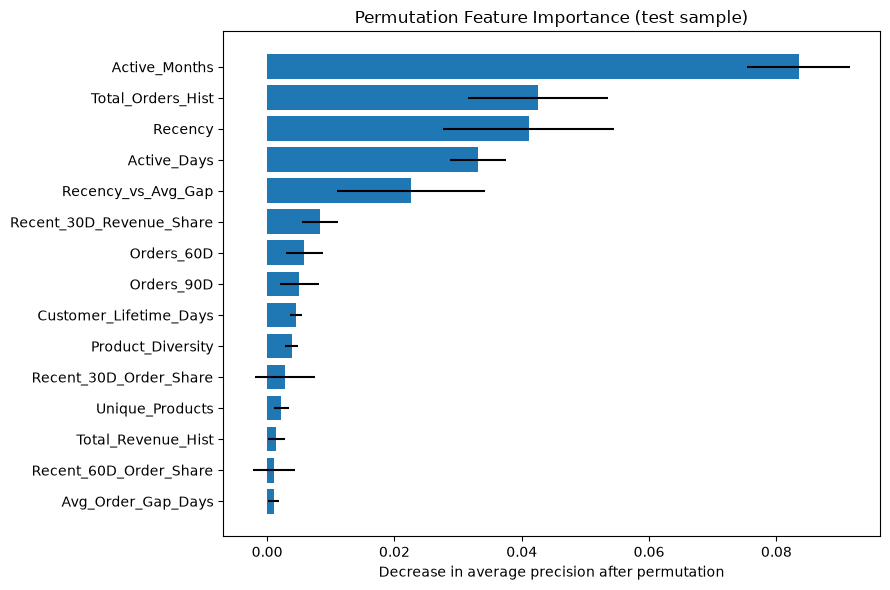

In [46]:
# Permutation importance is model-agnostic and avoids silently skipping explainability when SHAP is absent.
importance_sample = X_test.sample(n=min(1000, len(X_test)), random_state=RANDOM_STATE)
y_importance = y_test.loc[importance_sample.index]
perm = permutation_importance(
    final_model, importance_sample, y_importance,
    scoring="average_precision", n_repeats=5,
    random_state=RANDOM_STATE, n_jobs=-1
)
importance_df = pd.DataFrame({
    "Feature": importance_sample.columns,
    "PR_AUC_Importance_Mean": perm.importances_mean,
    "PR_AUC_Importance_Std": perm.importances_std
}).sort_values("PR_AUC_Importance_Mean", ascending=False)
display(importance_df.head(15))
plt.figure(figsize=(9, 6))
plot_imp = importance_df.head(15).sort_values("PR_AUC_Importance_Mean")
plt.barh(plot_imp["Feature"], plot_imp["PR_AUC_Importance_Mean"], xerr=plot_imp["PR_AUC_Importance_Std"])
plt.xlabel("Decrease in average precision after permutation")
plt.title("Permutation Feature Importance (test sample)")
plt.tight_layout()
plt.show()


## 12. Probability Calibration Check


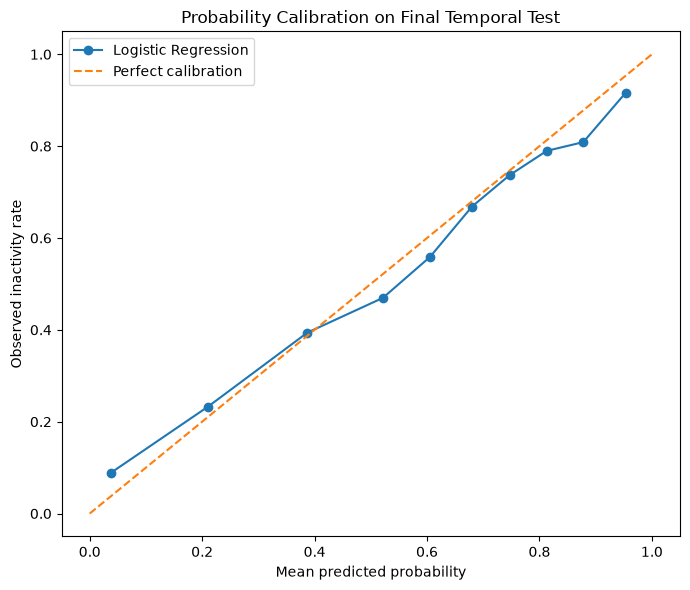

Model Brier score: 0.1816
Training-prior baseline Brier score: 0.2460
Lower Brier is better; also inspect the calibration plot and prevalence before claiming well-calibrated probabilities.


In [47]:
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier

prob_true, prob_pred = calibration_curve(y_test, y_prob_test, n_bins=10, strategy="quantile")
# Prior-only reference fitted on training + validation labels, not the final test labels.
prior_model = DummyClassifier(strategy="prior")
prior_model.fit(X_train_val, y_train_val)
prior_prob_test = prior_model.predict_proba(X_test)[:, 1]
model_brier = brier_score_loss(y_test, y_prob_test)
prior_brier = brier_score_loss(y_test, prior_prob_test)
plt.figure(figsize=(7, 6))
plt.plot(prob_pred, prob_true, marker="o", label=selected_model_name)
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed inactivity rate")
plt.title("Probability Calibration on Final Temporal Test")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Model Brier score: {model_brier:.4f}")
print(f"Training-prior baseline Brier score: {prior_brier:.4f}")
print("Lower Brier is better; also inspect the calibration plot and prevalence before claiming well-calibrated probabilities.")


## 13. Customer Risk Scoring & Prioritization

The score output is a retrospective test-snapshot analysis. `Customer_Value` means historical revenue only. `Risk_Weighted_Historical_Revenue = historical revenue × predicted inactivity probability` is a sorting heuristic, **not expected future revenue loss**. Actual labels are retained only in a separate evaluation table, never in the operational scoring export.


In [48]:
risk_profile = test_data[[
    "Customer ID", "Total_Revenue_Hist", "Total_Orders_Hist", "Total_Quantity_Hist",
    "Active_Days", "Active_Months", "Orders_30D", "Revenue_30D", "Orders_60D",
    "Revenue_60D", "Orders_90D", "Revenue_90D", "Recency", "Unique_Products", "Churn_90D"
]].copy()
risk_profile["Actual_Churn"] = risk_profile["Churn_90D"].astype(int)  # evaluation-only column
risk_profile["Churn_Probability"] = y_prob_test
risk_profile["Predicted_Churn"] = y_pred_test
risk_profile["Customer_Value"] = risk_profile["Total_Revenue_Hist"]
risk_profile["Risk_Weighted_Historical_Revenue"] = risk_profile["Customer_Value"] * risk_profile["Churn_Probability"]

risk_profile["Risk_Level"] = pd.cut(
    risk_profile["Churn_Probability"], bins=[-np.inf, 0.40, 0.70, np.inf],
    labels=["Low Risk", "Medium Risk", "High Risk"], include_lowest=True
)
value_threshold = risk_profile["Customer_Value"].quantile(0.75)
risk_profile["Value_Level"] = np.where(risk_profile["Customer_Value"] >= value_threshold, "High Historical Value", "Standard Historical Value")
risk_profile["Priority_Segment"] = np.select(
    [
        (risk_profile["Risk_Level"] == "High Risk") & (risk_profile["Value_Level"] == "High Historical Value"),
        risk_profile["Risk_Level"] == "High Risk",
        (risk_profile["Risk_Level"] == "Medium Risk") & (risk_profile["Value_Level"] == "High Historical Value"),
        risk_profile["Risk_Level"] == "Medium Risk",
        (risk_profile["Risk_Level"] == "Low Risk") & (risk_profile["Value_Level"] == "High Historical Value")
    ],
    ["High Risk - High Historical Value", "High Risk - Standard Value",
     "Medium Risk - High Historical Value", "Medium Risk - Standard Value",
     "Low Risk - High Historical Value"],
    default="Low Risk - Standard Value"
)
risk_profile["Action_Priority"] = risk_profile["Priority_Segment"].map({
    "High Risk - High Historical Value": "Review for retention outreach",
    "High Risk - Standard Value": "Low-cost reactivation test",
    "Medium Risk - High Historical Value": "Preventive engagement review",
    "Medium Risk - Standard Value": "Targeted engagement test",
    "Low Risk - High Historical Value": "Loyalty / upsell review",
    "Low Risk - Standard Value": "Standard marketing"
})
priority_summary = risk_profile.groupby("Priority_Segment", observed=True).agg(
    Customers=("Customer ID", "count"),
    Avg_Churn_Probability=("Churn_Probability", "mean"),
    Historical_Revenue=("Customer_Value", "sum"),
    Risk_Weighted_Historical_Revenue=("Risk_Weighted_Historical_Revenue", "sum")
).sort_values("Risk_Weighted_Historical_Revenue", ascending=False).round(2)
print("75th-percentile historical revenue cutoff:", round(value_threshold, 2))
display(priority_summary)


75th-percentile historical revenue cutoff: 2078.54


,Customers,Avg_Churn_Probability,Historical_Revenue,Risk_Weighted_Historical_Revenue
Priority_Segment,,,,
High Risk - Standard Value,2148,0.84,944437.45,771198.72
Medium Risk - Standard Value,1446,0.58,1225537.85,698783.56
Low Risk - High Historical Value,993,0.14,9603540.95,653526.35
Medium Risk - High Historical Value,254,0.53,1155298.84,616779.33
High Risk - High Historical Value,74,0.81,539040.88,453659.88
Low Risk - Standard Value,366,0.28,462700.05,124994.58


## 14. Risk & Revenue Analysis


In [49]:
risk_summary = risk_profile.groupby("Risk_Level", observed=True).agg(
    Customers=("Customer ID", "count"),
    Avg_Churn_Probability=("Churn_Probability", "mean"),
    Actual_90D_Inactivity_Rate=("Actual_Churn", "mean"),  # retrospective evaluation only
    Historical_Revenue=("Customer_Value", "sum"),
    Risk_Weighted_Historical_Revenue=("Risk_Weighted_Historical_Revenue", "sum"),
    Avg_Recency=("Recency", "mean")
).round(3)
display(risk_summary)
print("\nTop high-risk / high-historical-value customers (evaluation view):")
display(
    risk_profile[risk_profile["Priority_Segment"] == "High Risk - High Historical Value"]
    .sort_values("Risk_Weighted_Historical_Revenue", ascending=False)
    [["Customer ID", "Customer_Value", "Churn_Probability", "Risk_Weighted_Historical_Revenue", "Recency", "Orders_90D", "Revenue_90D", "Action_Priority"]]
    .head(20)
)


,Customers,Avg_Churn_Probability,Actual_90D_Inactivity_Rate,Historical_Revenue,Risk_Weighted_Historical_Revenue,Avg_Recency
Risk_Level,,,,,,
Low Risk,1359,0.175,0.211,1.006624e+07,778520.922,45.536
Medium Risk,1700,0.573,0.530,2.380837e+06,1315562.888,132.238
High Risk,2222,0.841,0.811,1.483478e+06,1224858.597,362.510



Top high-risk / high-historical-value customers (evaluation view):


,Customer ID,Customer_Value,Churn_Probability,Risk_Weighted_Historical_Revenue,Recency,Orders_90D,Revenue_90D,Action_Priority
11391,12346.0,77556.46,0.751632,58293.936120,234,0.0,0.0,Review for retention outreach
16278,17850.0,51208.87,1.000000,51208.866880,281,0.0,0.0,Review for retention outreach
12755,13902.0,34095.26,0.983016,33516.186970,541,0.0,0.0,Review for retention outreach
11515,12482.0,23691.40,0.990195,23459.116187,485,0.0,0.0,Review for retention outreach
12902,14063.0,22710.20,0.774413,17587.079901,347,0.0,0.0,Review for retention outreach
16636,18251.0,21964.14,0.700556,15387.109472,354,0.0,0.0,Review for retention outreach
15927,17448.0,14523.67,0.977645,14198.990970,406,0.0,0.0,Review for retention outreach
14418,15760.0,13916.34,0.957461,13324.359489,539,0.0,0.0,Review for retention outreach
12565,13687.0,11880.84,0.979420,11636.334458,347,0.0,0.0,Review for retention outreach
11890,12918.0,10953.50,0.953565,10444.875222,535,0.0,0.0,Review for retention outreach


In [50]:
action_summary = risk_profile.groupby("Action_Priority", observed=True).agg(
    Customers=("Customer ID", "count"),
    Historical_Revenue=("Customer_Value", "sum"),
    Risk_Weighted_Historical_Revenue=("Risk_Weighted_Historical_Revenue", "sum"),
    Avg_Churn_Probability=("Churn_Probability", "mean")
).sort_values("Risk_Weighted_Historical_Revenue", ascending=False).round(2)
display(action_summary)


,Customers,Historical_Revenue,Risk_Weighted_Historical_Revenue,Avg_Churn_Probability
Action_Priority,,,,
Low-cost reactivation test,2148,944437.45,771198.72,0.84
Targeted engagement test,1446,1225537.85,698783.56,0.58
Loyalty / upsell review,993,9603540.95,653526.35,0.14
Preventive engagement review,254,1155298.84,616779.33,0.53
Review for retention outreach,74,539040.88,453659.88,0.81
Standard marketing,366,462700.05,124994.58,0.28


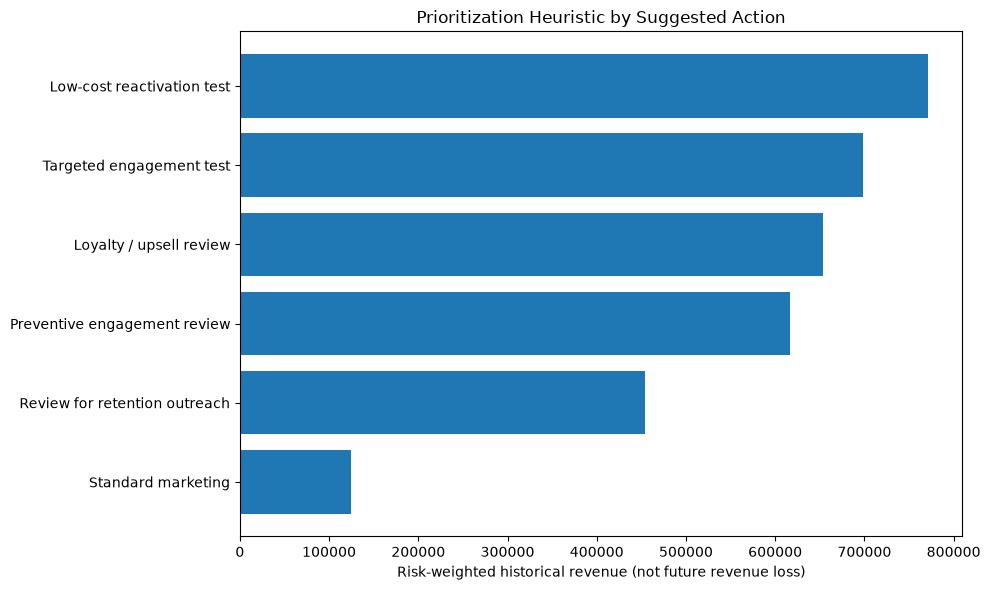

In [51]:
plot_data = action_summary.sort_values("Risk_Weighted_Historical_Revenue", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(plot_data.index, plot_data["Risk_Weighted_Historical_Revenue"])
plt.xlabel("Risk-weighted historical revenue (not future revenue loss)")
plt.title("Prioritization Heuristic by Suggested Action")
plt.tight_layout()
plt.show()


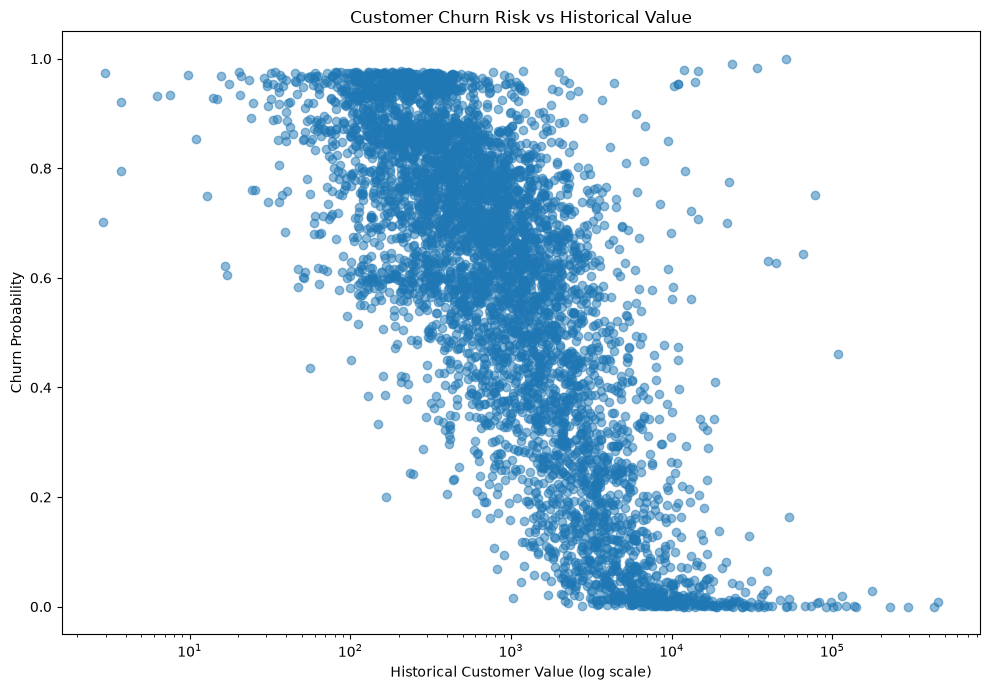

In [52]:
# Customer value vs churn probability
plt.figure(figsize=(10, 7))
plt.scatter(risk_profile["Customer_Value"], risk_profile["Churn_Probability"], alpha=0.5)
plt.xscale("log")
plt.xlabel("Historical Customer Value (log scale)")
plt.ylabel("Churn Probability")
plt.title("Customer Churn Risk vs Historical Value")
plt.tight_layout()
plt.show()


## 15. Final Customer Risk Output

This output is designed for a dashboard or retention workflow. It contains one row per eligible customer in the final test snapshot.


In [53]:
# Operational scoring output: no future actual label is included.
scoring_columns = [
    "Customer ID", "Churn_Probability", "Predicted_Churn", "Risk_Level",
    "Customer_Value", "Risk_Weighted_Historical_Revenue", "Priority_Segment",
    "Action_Priority", "Recency", "Orders_30D", "Revenue_30D", "Orders_90D",
    "Revenue_90D", "Total_Orders_Hist", "Unique_Products"
]
final_customer_output = risk_profile[scoring_columns].sort_values(
    "Risk_Weighted_Historical_Revenue", ascending=False
).copy()
final_customer_output["Model_Name"] = selected_model_name
final_customer_output["Decision_Threshold"] = best_threshold
final_customer_output["Scoring_Snapshot_Date"] = str(snapshot_dates[3].date())
print("Customers scored:", len(final_customer_output))
print("Total historical customer value:", round(final_customer_output["Customer_Value"].sum(), 2))
print("Risk-weighted historical revenue (heuristic only):", round(final_customer_output["Risk_Weighted_Historical_Revenue"].sum(), 2))
display(final_customer_output.head(20))

# Separate evaluation file for retrospective model diagnostics; do not use it as a future scoring feed.
evaluation_output = final_customer_output[["Customer ID", "Churn_Probability", "Predicted_Churn"]].merge(
    risk_profile[["Customer ID", "Actual_Churn"]], on="Customer ID", how="left", validate="one_to_one"
)


Customers scored: 5281
Total historical customer value: 13930556.02
Risk-weighted historical revenue (heuristic only): 3318942.41


,Customer ID,Churn_Probability,Predicted_Churn,Risk_Level,Customer_Value,Risk_Weighted_Historical_Revenue,Priority_Segment,Action_Priority,Recency,Orders_30D,Revenue_30D,Orders_90D,Revenue_90D,Total_Orders_Hist,Unique_Products,Model_Name,Decision_Threshold,Scoring_Snapshot_Date
11391,12346.0,0.751632,1,High Risk,77556.46,58293.936120,High Risk - High Historical Value,Review for retention outreach,234,0.0,0.0,0.0,0.00,12,27,Logistic Regression,0.45,2011-09-09
16278,17850.0,1.000000,1,High Risk,51208.87,51208.866880,High Risk - High Historical Value,Review for retention outreach,281,0.0,0.0,0.0,0.00,155,100,Logistic Regression,0.45,2011-09-09
13800,15061.0,0.460657,1,Medium Risk,108429.88,49949.016381,Medium Risk - High Historical Value,Preventive engagement review,36,0.0,0.0,7.0,5294.38,116,120,Logistic Regression,0.45,2011-09-09
15306,16754.0,0.643025,1,Medium Risk,65500.07,42118.157685,Medium Risk - High Historical Value,Preventive engagement review,281,0.0,0.0,0.0,0.00,29,38,Logistic Regression,0.45,2011-09-09
12755,13902.0,0.983016,1,High Risk,34095.26,33516.186970,High Risk - High Historical Value,Review for retention outreach,541,0.0,0.0,0.0,0.00,5,58,Logistic Regression,0.45,2011-09-09
14408,15749.0,0.627949,1,Medium Risk,44534.30,27965.262252,Medium Risk - High Historical Value,Preventive engagement review,144,0.0,0.0,0.0,0.00,3,5,Logistic Regression,0.45,2011-09-09
13833,15098.0,0.631403,1,Medium Risk,39916.50,25203.404765,Medium Risk - High Historical Value,Preventive engagement review,91,0.0,0.0,0.0,0.00,3,1,Logistic Regression,0.45,2011-09-09
11515,12482.0,0.990195,1,High Risk,23691.40,23459.116187,High Risk - High Historical Value,Review for retention outreach,485,0.0,0.0,0.0,0.00,29,42,Logistic Regression,0.45,2011-09-09
12902,14063.0,0.774413,1,High Risk,22710.20,17587.079901,High Risk - High Historical Value,Review for retention outreach,347,0.0,0.0,0.0,0.00,9,30,Logistic Regression,0.45,2011-09-09
16636,18251.0,0.700556,1,High Risk,21964.14,15387.109472,High Risk - High Historical Value,Review for retention outreach,354,0.0,0.0,0.0,0.00,8,77,Logistic Regression,0.45,2011-09-09


In [54]:
# Save to ./outputs for a clean, portable repository layout.
from pathlib import Path
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)
scoring_path = output_dir / "customer_churn_scoring_output.csv"
evaluation_path = output_dir / "customer_churn_evaluation_output.csv"
metrics_path = output_dir / "customer_churn_model_metrics.csv"

final_customer_output.to_csv(scoring_path, index=False)
evaluation_output.to_csv(evaluation_path, index=False)
pd.DataFrame([final_metrics]).to_csv(metrics_path, index=False)
print("Operational scoring output:", scoring_path.resolve())
print("Retrospective evaluation output:", evaluation_path.resolve())
print("Model metrics:", metrics_path.resolve())


Operational scoring output: /Users/hardiksehdev/RICCE/Notebooks/outputs/customer_churn_scoring_output.csv
Retrospective evaluation output: /Users/hardiksehdev/RICCE/Notebooks/outputs/customer_churn_evaluation_output.csv
Model metrics: /Users/hardiksehdev/RICCE/Notebooks/outputs/customer_churn_model_metrics.csv


## 16. Final Business Interpretation

This notebook estimates **90-day purchase inactivity**, not permanent customer loss. The model output can support prioritization for a controlled retention test; it does not prove that contacting a flagged customer will prevent churn.

- `Customer_Value` is historical transaction revenue, not future customer lifetime value.
- `Risk_Weighted_Historical_Revenue` is a prioritization heuristic, not expected future revenue loss.
- Recommended actions are hypotheses for business testing, not optimized interventions.
- To estimate incremental retention or ROI, run a controlled campaign experiment and compare outcomes against a holdout group.
- Performance can shift with seasonality, changes in product mix, and customer purchase cadence; use rolling temporal backtesting before deployment.


## 17. Reproducibility & Limitations

- Random seed: `42`.
- Cutoff day is included in the observation window; the following 90 full calendar days define the inactivity label.
- Model selection uses validation PR-AUC (ROC-AUC as tie-breaker); threshold is chosen using validation recall/precision only.
- Final temporal test results are reported after model and threshold are frozen.
- The final test snapshot is one time period, not enough evidence for production reliability; add rolling-origin backtesting before deployment.
